## Para que funcione
Es necesario cambiar la version de Python a la 3.12.10, ya que la .14 no tiene soporte de tensorflow

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

In [2]:
x_train.shape[0]

60000

In [3]:
gray_scale = 255

# Se les aplica una transformacion a valores de 0-1
x_train = x_train.astype('float32') / gray_scale
x_test = x_test.astype('float32') / gray_scale

print("Feature matrix (x_train):", x_train.shape)
print("Target matrix (y_train):", y_train.shape)
print("Feature matrix (x_test):", x_test.shape)
print("Target matrix (y_test):", y_test.shape)

Feature matrix (x_train): (60000, 28, 28)
Target matrix (y_train): (60000,)
Feature matrix (x_test): (10000, 28, 28)
Target matrix (y_test): (10000,)


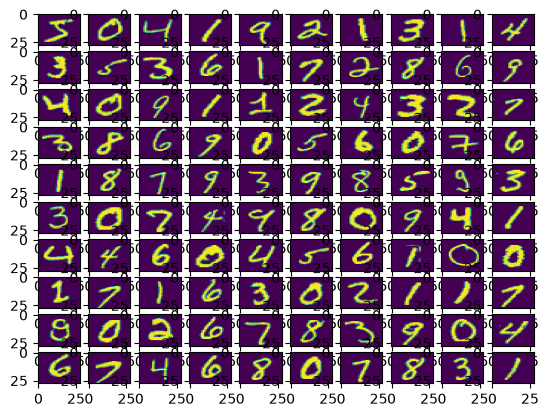

In [4]:
fig, ax = plt.subplots(10, 10)
k = 0
for i in range(10):
    for j in range(10):
        ax[i][j].imshow(x_train[k].reshape(28, 28), aspect='auto')
        k += 1
plt.show()

In [18]:
model = Sequential([
    Flatten(input_shape=(28, 28)),      #aplanamiento, transforma matrices a un solo array, generara las 784 entradas (28x28)
    Dense(256, activation='sigmoid'),   
    Dense(128, activation='sigmoid'), 
    Dense(10, activation='softmax'),    #Normalmente se ve en la capa de salida (estandar). Sumatoria de todas las capas de salida de 1.
                                        #tendremos 10 valores pequeños que sumados den 1. Aquella neurona que tenga el valor mayor se va activar.
])                                      #Transforma 

In [19]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy', #Le ayuda al modelo a tener una mayor precisión
              metrics=['accuracy'])

In [ ]:
# Entrenamiento del modelo
mod = model.fit(x_train, y_train, epochs=25, 
          batch_size=2000, 
          validation_split=0.2)
          
print(mod)

# Experimento
# from tensorflow.keras.callbacks import EarlyStopping

# parar = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

# mod = model.fit(x_train, y_train, epochs=50,
#                 batch_size=2000,
#                 validation_split=0.2,
#                 callbacks=[parar])

Epoch 1/25
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.3825 - loss: 2.0902 - val_accuracy: 0.7079 - val_loss: 1.7464
Epoch 2/25
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.7399 - loss: 1.4144 - val_accuracy: 0.8093 - val_loss: 1.0607
Epoch 3/25
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.8182 - loss: 0.8839 - val_accuracy: 0.8610 - val_loss: 0.6820
Epoch 4/25
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8639 - loss: 0.6104 - val_accuracy: 0.8857 - val_loss: 0.4973
Epoch 5/25
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8869 - loss: 0.4730 - val_accuracy: 0.9003 - val_loss: 0.4045
Epoch 6/25
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8980 - loss: 0.3987 - val_accuracy: 0.9079 - val_loss: 0.3522
Epoch 7/25
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9060 - loss: 0.3534 - val_accuracy: 0.9129 - val_loss: 0.3184
Epoch 8/25
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9118 - loss: 0.3224 - val_accuracy: 0.9187 - v

In [21]:
results = model.evaluate(x_test, y_test, verbose=0)
print('Test loss, Test accuracy:', results)

Test loss, Test accuracy: [0.15641646087169647, 0.9538000226020813]


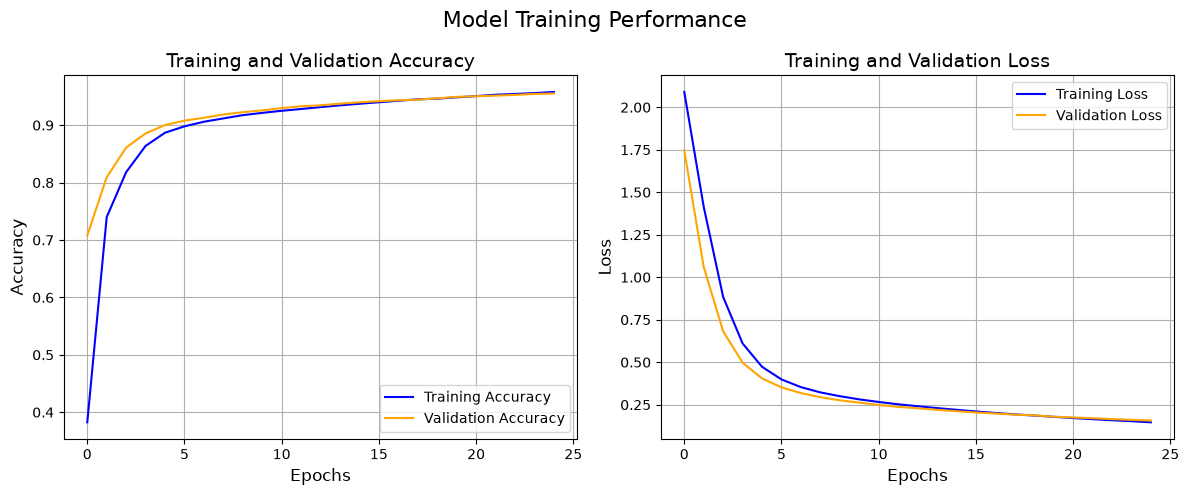

In [22]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(mod.history['accuracy'], label='Training Accuracy', color='blue')
plt.plot(mod.history['val_accuracy'],
         label='Validation Accuracy', color='orange')
plt.title('Training and Validation Accuracy', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(mod.history['loss'], label='Training Loss', color='blue')
plt.plot(mod.history['val_loss'], label='Validation Loss', color='orange')
plt.title('Training and Validation Loss', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend()
plt.grid(True)

plt.suptitle("Model Training Performance", fontsize=16)
plt.tight_layout()
plt.show()

In [23]:
# Guardar el modelo
#model.save("modelo_mnist.keras")
model.save("modelo_mnist_25.keras")

   ## Pruebas realizadas

   | Prueba | Épocas | Precisión en prueba |
   |---|---|---|
   | Código original | 10 | 92.6 % |
   | Con EarlyStopping (llegó al máximo) | 50 | 97.3 % | 
   | Código original (modelo guardado) | 25 | 95.4 % |

   Con 10 épocas el modelo todavía estaba aprendiendo, porque la pérdida de validación seguía bajando. Con 25 épocas el entrenamiento y la validación van parejos, sin sobreentrenamiento. Se guardó el modelo de 25 épocas.